<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">DATOS MASIVOS II · PRÁCTICA</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">PageRank sensible a tópico en Wikipedia</div><div style="opacity:.72;font-size:14px;margin-top:6px;">Qué es importante dentro de cada tema.</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Equipo Tres: Castrillo Cruz Karen Arlet, Ramos González Nadia, Zamora Antiga Ángel Javier.</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

### Objetivo

El PageRank del notebook 2 da una sola lista para todos. Aquí preguntamos otra cosa: **¿qué es importante dentro de un tema?**

Hacemos cuatro cosas:

1. Definimos 32 temas con las categorías de Wikipedia.
2. Calculamos un PageRank por tema, y lo ordenamos para que se vea lo propio de cada uno.
3. Corremos HITS dentro de cada tema para ver sus hubs y autoridades.
4. Comprobamos si estos puntajes permiten adivinar el tema de un artículo.

También probamos cómo responder a un lector con varios intereses sin volver a calcular nada.

### Datos

Usamos la matriz de enlaces y el PageRank general del notebook 2, y las categorías de cada artículo del notebook 1.

In [1]:
# Librerías, rutas, paleta y funciones auxiliares de estilo
import re
import sys
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.dataset as ds
import pyarrow.parquet as pq
import scipy.sparse as sp
from matplotlib.colors import LinearSegmentedColormap
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr
from IPython.display import display

sys.path.insert(0, "..")   # registro.py está en la carpeta Wikipedia/
import registro as reg

NB = "03_topic_sensitive"  # carpeta de resultados: data/resultados/03_topic_sensitive/

%matplotlib inline
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 80)

GRAFO = Path("..") / "data" / "grafo"
ARCHIVO_MATRIZ = GRAFO / "adyacencia.npz"
ARCHIVO_PUNTAJES = GRAFO / "puntajes.parquet"
SEMILLA = 42
BETA = 0.85

# Paleta única del notebook: azul principal, rojo de acento y grises neutros
AZUL, ROJO = "#3D6FB0", "#B03D3D"
GRIS, GRIS_CLARO, TINTA = "#8C8C8C", "#EEF1F6", "#333333"
CMAP_SEC = LinearSegmentedColormap.from_list("azules", plt.cm.Blues(np.linspace(0.22, 1, 256)))
CMAP_SEC.set_bad("white")

plt.rcParams.update({
    "figure.dpi": 100, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": "#999999", "axes.labelcolor": TINTA,
    "xtick.color": TINTA, "ytick.color": TINTA, "legend.frameon": False,
})


def estilo_ejes(ax, titulo=None, xlabel=None, ylabel=None, rejilla="y"):
    """
    Aplica el estilo común a unos ejes de matplotlib.

    Parámetros
    ----------
    ax : matplotlib.axes.Axes
        Ejes a formatear.
    titulo, xlabel, ylabel : str, opcional
        Título y etiquetas de los ejes (con unidades).
    rejilla : {"x", "y", "both", None}
        Eje sobre el que se dibuja una rejilla tenue.
    """
    if titulo:
        ax.set_title(titulo)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.spines[["top", "right"]].set_visible(False)
    if rejilla:
        ax.grid(axis=rejilla, color="#DDDDDD", linewidth=0.6)
        ax.set_axisbelow(True)


def pct(x, dec=2):
    """Formatea una proporción como porcentaje con espacio antes del símbolo."""
    return f"{100 * x:,.{dec}f} %"


def jaccard_top(a, b, k):
    """
    Índice de Jaccard entre los k nodos con mayor puntaje de dos rankings.

    Parámetros
    ----------
    a, b : np.ndarray
        Puntajes por índice de nodo.
    k : int
        Tamaño del top.

    Retorna
    -------
    float
        |top_a ∩ top_b| / |top_a ∪ top_b|.
    """
    ta, tb = np.argpartition(-a, k)[:k], np.argpartition(-b, k)[:k]
    comun = len(np.intersect1d(ta, tb))
    return comun / (2 * k - comun)

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · DATOS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">1. Datos y verificación</span></div>

Cargamos la matriz y comprobamos que coincide con la tabla de nodos: los mismos artículos en el mismo orden y los mismos grados. Después quitamos las páginas de desambiguación, igual que en el notebook 2.

In [2]:
# Carga de la matriz y su mapeo, verificación contra nodos y grafo de análisis
inicio = time.time()
A = sp.load_npz(ARCHIVO_MATRIZ)
ids = np.load(ARCHIVO_MATRIZ)["ids"]
nodos = pq.read_table(GRAFO / "nodos").to_pandas().sort_values("idx").reset_index(drop=True)
verificacion = pd.Series({
    "Dimensión de A = número de nodos": A.shape == (len(nodos), len(nodos)),
    "Mismos page_id en el mismo orden": np.array_equal(ids, nodos["id"].to_numpy()),
    "Grados de salida iguales": np.array_equal(np.asarray(A.sum(axis=1)).ravel(), nodos["grado_salida"].to_numpy()),
    "Grados de entrada iguales": np.array_equal(np.asarray(A.sum(axis=0)).ravel(), nodos["grado_entrada"].to_numpy()),
}, name="Se cumple").to_frame()
display(verificacion)
assert verificacion["Se cumple"].all()

conserva = ~nodos["is_disambig"].to_numpy()
A_an = A[conserva][:, conserva].tocsr()
del A
nodos_an = nodos[conserva].reset_index(drop=True)
n = len(nodos_an)
k_out = np.asarray(A_an.sum(axis=1)).ravel()
k_in = np.asarray(A_an.sum(axis=0)).ravel()
inv_k_out = np.divide(1.0, k_out, out=np.zeros(n), where=k_out > 0)

BLOQUES = 16
POOL = ThreadPoolExecutor(BLOQUES)


def partir(X, bloques=BLOQUES):
    """Divide una matriz CSR en bloques consecutivos de filas (ver notebook 2)."""
    cortes = np.linspace(0, X.shape[0], bloques + 1).astype(int)
    return [X[a:b] for a, b in zip(cortes[:-1], cortes[1:])]


def producto(bloques, x):
    """Calcula X @ x multiplicando en paralelo los bloques de filas de X (ver notebook 2)."""
    return np.concatenate(list(POOL.map(lambda bloque: bloque @ x, bloques)))


A_bloques = partir(A_an)
AT_bloques = partir(A_an.T.tocsr())
m = A_an.nnz
del A_an   # basta con los bloques

puntajes = pd.read_parquet(ARCHIVO_PUNTAJES)
assert np.array_equal(puntajes["id"].to_numpy(), nodos_an["id"].to_numpy())
pr_general = puntajes["pagerank"].to_numpy()
residuo = BETA * producto(AT_bloques, pr_general * inv_k_out)
residuo = np.abs(residuo + (1 - residuo.sum()) / n - pr_general).sum()
if residuo > 1e-9:
    reg.nota(f"03: el PageRank general guardado tiene un residuo de {residuo:.2e} en el grafo de análisis")
print(f"Grafo de análisis: {n:,} artículos y {m:,} enlaces | residuo del PageRank general guardado: {residuo:.1e}")
verificacion.loc["Residuo del PageRank general guardado"] = residuo
reg.registrar_paso("03.1", inicio, [reg.guardar_tabla(verificacion, "01_verificacion", NB)], f"{n:,} artículos y {m:,} enlaces")

,Se cumple
Dimensión de A = número de nodos,True
Mismos page_id en el mismo orden,True
Grados de salida iguales,True
Grados de entrada iguales,True


Grafo de análisis: 6,879,374 artículos y 233,221,445 enlaces | residuo del PageRank general guardado: 6.5e-11


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · TÓPICOS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">2. Tópicos con las categorías de Wikipedia</span></div>

**De dónde salen.** Los editores asignan categorías a cada artículo, y las categorías tienen otras categorías dentro. La raíz temática se llama *Main topic classifications*. Sus subcategorías son nuestros temas, salvo *Lists* y *Main topic articles*, que no son temas. Quedan 32.

**Cómo se asigna un artículo a un tema.** Medimos a cuántos niveles está de cada raíz. Si $c$ es una categoría del artículo $i$ y $d_T(c)$ es su distancia a la raíz del tema $T$:

$$d_T(i) = 1 + \min_{c \,\ni\, i} d_T(c)$$

El artículo pertenece al tema o temas más cercanos, siempre que estén a 8 niveles o menos:

$$\text{temas}(i) = \{\, T : d_T(i) = \min_{T'} d_{T'}(i) \,\}, \qquad \text{si } \min_{T'} d_{T'}(i) \le 8$$

Si hay empate, pertenece a varios.

**Limpieza.** Antes quitamos categorías administrativas, como *Articles with…* o *CS1…*, porque no dicen de qué trata el artículo.

In [3]:
# Grafo de categorías (madre → hija) sin categorías de mantenimiento y distancias desde cada raíz
inicio = time.time()
jerarquia = pq.read_table(GRAFO / "jerarquia_categorias").to_pandas()
cat_art = ds.dataset(GRAFO / "categorias_nodo").to_table().to_pandas()
MANTENIMIENTO = re.compile(
    r"^(Wikipedia|Articles?\b|All articles|Pages?\b|CS1|Webarchive|Use |Short description|Commons|Hidden categories|"
    r"Tracking categories|Container categories|Template|Redirects?\b|User |Stub|Good articles|Featured |Coordinates|"
    r"Accuracy disputes|Orphaned|Dead |AC with|Noindexed|Infobox|Official website|Disambiguation)", re.IGNORECASE)

codigos, nombres = pd.factorize(np.concatenate([jerarquia["categoria"].to_numpy(object), jerarquia["padre"].to_numpy(object),
                                                cat_art["category"].to_numpy(object)]))
nombres = pd.Index(nombres)
n_cat, n_rel = len(nombres), len(jerarquia)
hija, madre, cat_de_art = codigos[:n_rel], codigos[n_rel:2 * n_rel], codigos[2 * n_rel:]
es_mant = np.asarray(nombres.str.match(MANTENIMIENTO), dtype=bool)
ok = ~es_mant[hija] & ~es_mant[madre]
C = sp.csr_matrix((np.ones(ok.sum()), (madre[ok], hija[ok])), shape=(n_cat, n_cat))

META = ["Lists", "Main topic articles"]
hijas_raiz = sorted(nombres[C[nombres.get_loc("Main topic classifications")].indices])
TOPICOS = [t for t in hijas_raiz if t not in META]
K = len(TOPICOS)
t0 = time.perf_counter()
dist_cat = shortest_path(C, method="D", unweighted=True, indices=nombres.get_indexer(TOPICOS)).astype(np.float32)
print(f"Categorías: {n_cat:,} ({es_mant.sum():,} de mantenimiento) | relaciones madre → hija: {ok.sum():,} | "
      f"BFS desde {K} raíces en {time.perf_counter() - t0:.0f} s")
print("Tópicos:", ", ".join(TOPICOS))

# Distancia de cada artículo del grafo de análisis a cada raíz: 1 + mínimo sobre sus categorías
posicion = np.full(nodos["id"].max() + 1, -1, dtype=np.int64)
posicion[nodos_an["id"].to_numpy()] = np.arange(n)
fila_art = posicion[cat_art["id"].to_numpy()]
valida = (fila_art >= 0) & ~es_mant[cat_de_art]
M_art = sp.csr_matrix((np.ones(valida.sum(), dtype=np.float32), (fila_art[valida], cat_de_art[valida])), shape=(n, n_cat))
M_art.sum_duplicates()
sin_categoria = np.diff(M_art.indptr) == 0
dist_art = np.full((n, K), np.inf, dtype=np.float32)
inicio_filas = M_art.indptr[:-1].clip(max=M_art.nnz - 1)
for t in range(K):
    minimo = np.minimum.reduceat(dist_cat[t][M_art.indices], inicio_filas)
    minimo[sin_categoria] = np.inf
    dist_art[:, t] = minimo + 1
d_min = dist_art.min(axis=1)
del cat_art, codigos, hija, madre, cat_de_art, fila_art

Categorías: 2,303,002 (29,528 de mantenimiento) | relaciones madre → hija: 5,023,193 | BFS desde 32 raíces en 14 s
Tópicos: Academic disciplines, Behavior, Communication, Concepts, Culture, Economy, Education, Energy, Engineering, Entities, Food and drink, Geography, Government, Health, History, Humanities, Humans, Information, Knowledge, Language, Law, Life, Mass media, Mathematics, Philosophy, Politics, Religion, Science, Society, Technology, Time, Universe


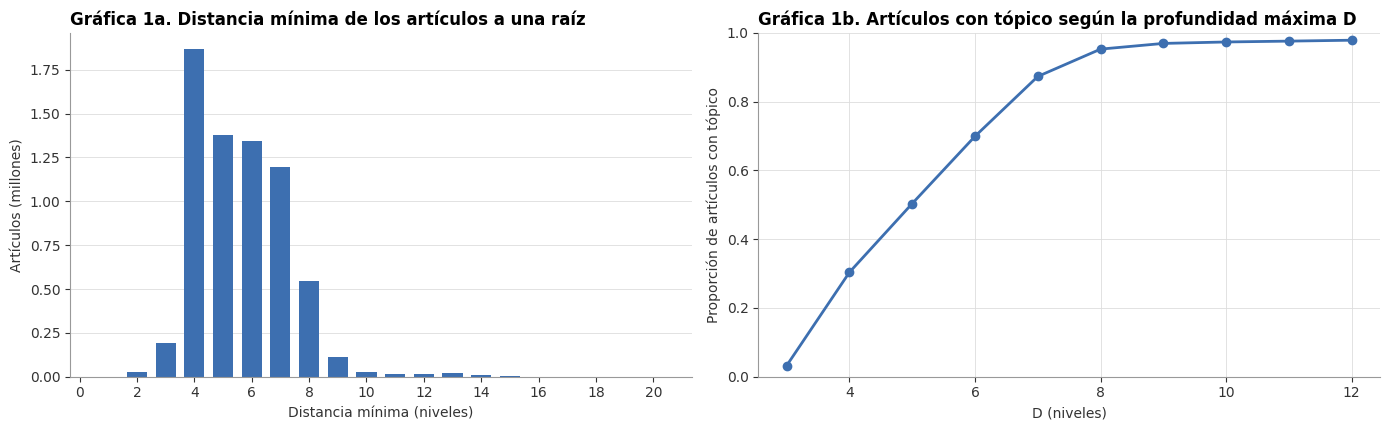

Artículos sin categorías temáticas: 76,982 (1.12 %) | con categorías pero sin camino a ninguna raíz: 36,564


,cobertura,tópicos por artículo,tópico mayor
D,,,
3,3.2%,1.31,8.8%
4,30.4%,1.28,58.5%
5,50.4%,1.51,41.1%
6,69.9%,1.66,33.5%
7,87.3%,1.74,31.4%
8,95.3%,1.80,29.6%
9,96.9%,1.81,29.3%
10,97.3%,1.81,29.2%
11,97.6%,1.81,29.1%


In [4]:
# Gráfica 1. Profundidad mínima de los artículos y cobertura según la profundidad máxima D
alcanzable = np.isfinite(d_min)
prof = pd.Series(d_min[alcanzable]).value_counts().sort_index()
filas = []
for D in range(3, 13):
    pert = (dist_art == d_min[:, None]) & (d_min[:, None] <= D)
    con = pert.any(axis=1)
    filas.append({"D": D, "cobertura": con.mean(), "tópicos por artículo": pert[con].sum(axis=1).mean(),
                  "tópico mayor": pert.sum(axis=0).max() / con.sum()})
cobertura = pd.DataFrame(filas).set_index("D")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.4))
ax1.bar(prof.index, prof.to_numpy() / 1e6, color=AZUL, width=0.7)
ax1.set_xticks(range(0, int(prof.index.max()) + 1, 2))
estilo_ejes(ax1, "Gráfica 1a. Distancia mínima de los artículos a una raíz", "Distancia mínima (niveles)",
            "Artículos (millones)")
ax2.plot(cobertura.index, cobertura["cobertura"], color=AZUL, marker="o", linewidth=2)
ax2.set_ylim(0, 1)
estilo_ejes(ax2, "Gráfica 1b. Artículos con tópico según la profundidad máxima D", "D (niveles)",
            "Proporción de artículos con tópico", rejilla="both")
plt.tight_layout()
archivo_g1 = reg.guardar_figura(fig, "grafica_01_profundidad_y_cobertura", NB)
plt.show()
print(f"Artículos sin categorías temáticas: {sin_categoria.sum():,} ({pct(sin_categoria.mean())}) | con categorías "
      f"pero sin camino a ninguna raíz: {(~sin_categoria & ~alcanzable).sum():,}")
display(cobertura.style.format({"cobertura": "{:.1%}", "tópicos por artículo": "{:.2f}", "tópico mayor": "{:.1%}"}))

**Observaciones.** En 1a, la mayoría de los artículos está a entre 4 y 7 niveles de una raíz, con el máximo en 4 (1.87 millones). Después de 8 niveles quedan muy pocos.

En 1b se ve por qué usamos 8: con 5 niveles solo tendrían tema el 50.4 % de los artículos, con 8 el 95.3 %, y con 12 apenas el 97.9 %. Bajar más casi no agrega artículos. Quedan 76,982 artículos (1.12 %) sin categorías temáticas y 36,564 con categorías que no llegan a ninguna raíz.

**Dos conjuntos distintos.** Con el límite de 8 niveles sabemos a qué tema pertenece casi cualquier artículo, pero un camino largo se puede desviar del tema. Por eso usamos dos conjuntos:

- **Pertenencia** (hasta 8 niveles): sirve para etiquetar y para medir.
- **Semillas** (hasta 5 niveles): son los artículos a los que salta el lector en el PageRank por tema. Son menos, pero están más cerca de la raíz.

In [5]:
# Pertenencia de los artículos a los tópicos con D = 8 y descripción de cada tópico
D = 8
pertenencia = (dist_art == d_min[:, None]) & (d_min[:, None] <= D)
con_topico = pertenencia.any(axis=1)
tam_topico = pertenencia.sum(axis=0)
del dist_art, M_art

# Semillas: los artículos del tema que están a 5 niveles o menos de una raíz
D_SEMILLA = 5
semilla = pertenencia & (d_min[:, None] <= D_SEMILLA)
S = semilla.astype(np.float32)
tam_semilla = semilla.sum(axis=0)
assert (tam_semilla > 0).all()

# Cohesión: proporción de los enlaces que salen de los artículos del tópico y llegan a artículos del tópico
P = pertenencia.astype(np.float32)
AP = producto(A_bloques, P)          # AP[i, t] = enlaces de i hacia artículos de t
cohesion = (P * AP).sum(axis=0) / (P * k_out[:, None]).sum(axis=0)
del AP

descripcion = pd.DataFrame({
    "artículos": tam_topico, "% del grafo": tam_topico / n, "semillas": tam_semilla,
    "exclusivos (un solo tópico)": (pertenencia & (pertenencia.sum(axis=1) == 1)[:, None]).sum(axis=0) / tam_topico,
    "cohesión": cohesion,
    "más enlazados": [", ".join(nodos_an.loc[np.where(pertenencia[:, t])[0][np.argsort(-k_in[pertenencia[:, t]])[:3]], "title"])
                      for t in range(K)],
}, index=pd.Index(TOPICOS, name="tópico")).sort_values("artículos", ascending=False)
print(f"Artículos con tópico: {con_topico.sum():,} ({pct(con_topico.mean())}) | tópicos por artículo: media "
      f"{pertenencia[con_topico].sum(axis=1).mean():.2f}, máximo {pertenencia.sum(axis=1).max()}")
display(descripcion.style.format({"artículos": "{:,}", "semillas": "{:,}", "% del grafo": "{:.2%}", "exclusivos (un solo tópico)": "{:.1%}",
                                  "cohesión": "{:.1%}"}))

Artículos con tópico: 6,553,675 (95.27 %) | tópicos por artículo: media 1.80, máximo 17


,artículos,% del grafo,semillas,exclusivos (un solo tópico),cohesión,más enlazados
tópico,,,,,,
Humans,"1,942,164",28.23%,"1,425,388",65.8%,21.0%,"Village, Moth, Los Angeles Times"
Culture,"1,327,842",19.30%,"393,229",21.6%,30.8%,"United States, AllMusic, Midfielder"
Geography,"1,032,657",15.01%,"155,807",40.8%,36.3%,"United States, Germany, U.S. state"
Society,"936,927",13.62%,"284,686",10.5%,22.7%,"United States, France, Germany"
Mass media,"850,504",12.36%,"393,501",42.4%,43.3%,"The New York Times, AllMusic, YouTube"
Government,"816,562",11.87%,"304,170",32.9%,37.2%,"United States, France, Germany"
History,"701,974",10.20%,"196,932",23.6%,19.6%,"India, Catholic Church, China"
Humanities,"449,669",6.54%,"210,733",14.7%,19.6%,"Romanization, Europe, Race and ethnicity in the United States census"
Technology,"373,999",5.44%,"190,355",20.3%,26.6%,"World War II, New York City, London"


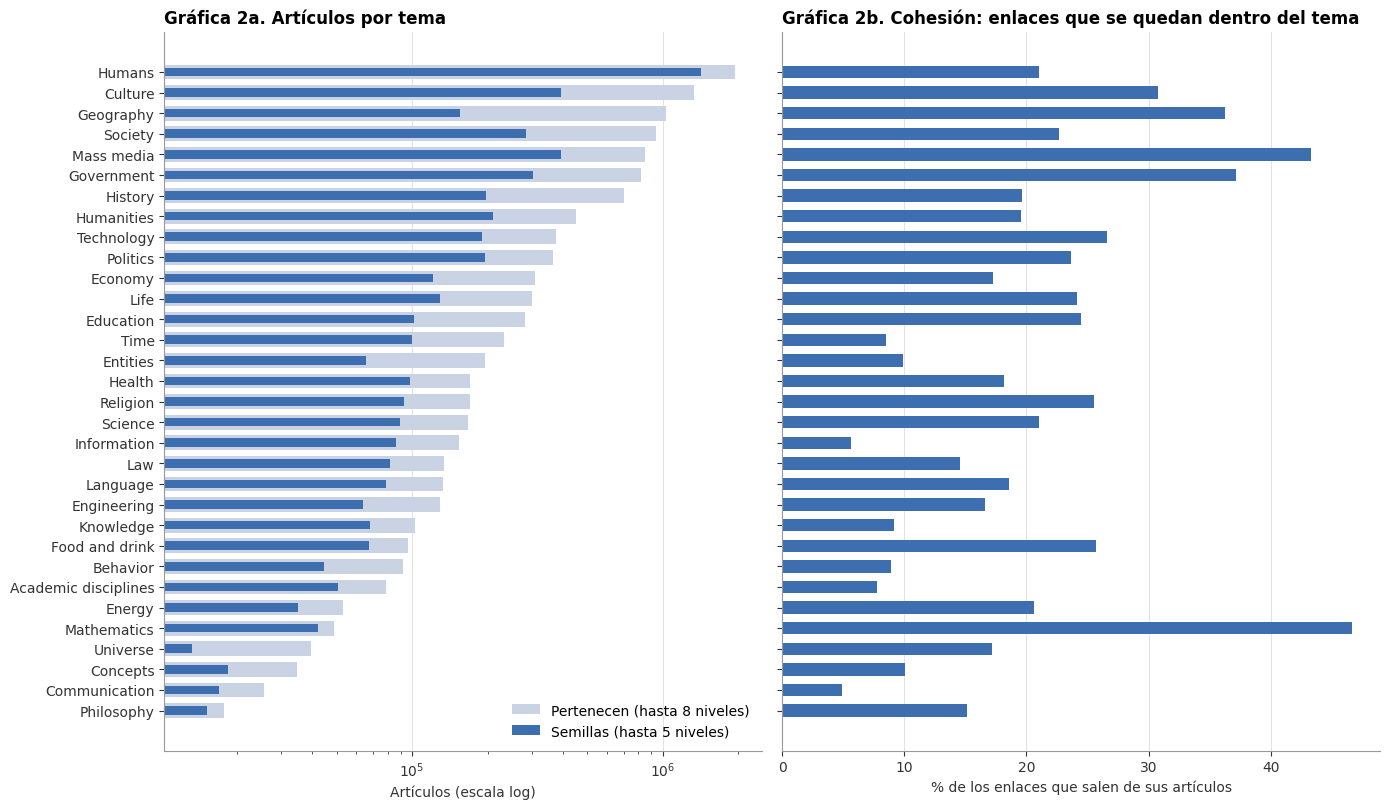

In [6]:
# Gráfica 2. Tamaño y cohesión de cada tema
orden = list(descripcion.index)
indice_topico = {t: i for i, t in enumerate(TOPICOS)}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 8.2), sharey=True)
posiciones = np.arange(K)[::-1]
ax1.barh(posiciones, descripcion["artículos"], color="#C9D3E3", height=0.72, label="Pertenecen (hasta 8 niveles)")
ax1.barh(posiciones, descripcion["semillas"], color=AZUL, height=0.42, label="Semillas (hasta 5 niveles)")
ax1.set_yticks(posiciones, labels=orden)
ax1.set_xscale("log")
estilo_ejes(ax1, "Gráfica 2a. Artículos por tema", "Artículos (escala log)", rejilla="x")
ax1.legend(loc="lower right")
ax2.barh(posiciones, 100 * descripcion["cohesión"], color=AZUL, height=0.6)
estilo_ejes(ax2, "Gráfica 2b. Cohesión: enlaces que se quedan dentro del tema", "% de los enlaces que salen de sus artículos", rejilla="x")
plt.tight_layout()
archivo_g2 = reg.guardar_figura(fig, "grafica_02_tamano_y_cohesion", NB)
plt.show()

topicos_de = np.array(["; ".join(np.array(TOPICOS)[fila]) for fila in pertenencia])
tabla_pertenencia = pd.DataFrame({"id": nodos_an["id"], "title": nodos_an["title"], "topicos": topicos_de, "distancia_minima": d_min})
reg.registrar_paso("03.2", inicio, [
    reg.guardar_parquet(tabla_pertenencia, "02_pertenencia", NB), reg.guardar_tabla(cobertura, "02_cobertura_por_D", NB),
    reg.guardar_tabla(descripcion, "02_descripcion_topicos", NB), archivo_g1, archivo_g2,
], f"{K} tópicos, D = {D}, {pct(con_topico.mean())} de los artículos con tópico")
del topicos_de, tabla_pertenencia

**Observaciones.** Los temas son muy desiguales: *Humans* tiene 109 veces más artículos que *Philosophy*. Por la barra oscura también se ve que las semillas no son la misma proporción en todos: el 86 % de *Mathematics*, pero solo el 15 % de *Geography*, porque la mayoría de sus artículos está lejos de la raíz.

En 2b, tamaño y cohesión no van de la mano. *Mathematics* es de los más pequeños y es el más cohesivo: el 46.6 % de sus enlaces se queda dentro. *Communication* e *Information* están alrededor de 5 %, así que como temas se sostienen poco con enlaces.

Con 8 niveles entran artículos que no se esperarían. Entre los más enlazados de cada tema aparecen *St. Louis Cardinals* en *Food and drink* y *Roger Ebert* en *Philosophy*. Esta es la razón para usar semillas más estrictas.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · TSPR</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3. PageRank por tema</span></div>

**La idea.** Es el mismo lector del notebook 2 con un solo cambio: cuando se aburre, no salta a cualquier artículo, sino a uno del tema. Así, todo lo que recorre queda cerca de ese tema.

**La fórmula.** Para un tema con conjunto de semillas $S$:

$$r_S = \beta M r_S + (1 - \beta)\,\frac{e_S}{|S|}$$

- $e_S$ vale 1 en los artículos de $S$ y 0 en los demás.
- $|S|$ es el número de semillas, así que el salto se reparte por igual entre ellas.
- Lo demás es igual que en PageRank. Usamos $\beta = 0.85$.

Un detalle útil para leer los resultados: el salto entrega en cada paso el 15 % de la probabilidad a las semillas. Por eso la parte del vector que queda dentro del tema nunca baja de $1 - \beta = 15\,\%$.

**Lo propio del tema.** Si ordenamos por $r_S$, arriba aparecen *United States* o *The New York Times*, porque el lector llega a ellos desde cualquier tema. Queremos lo que el tema sube respecto al PageRank general $r$. Para eso usamos la **especificidad**:

$$\text{esp}_S(i) = r_S(i)\,\ln \frac{r_S(i)}{r(i)}$$

- $r_S(i) / r(i)$ dice cuántas veces sube el artículo con este tema. Si no sube, el logaritmo vale cero o menos.
- $r_S(i)$ evita que suban artículos muy raros que apenas tienen puntaje.

**Ejemplo.** Un artículo con $r_S = 0.001$ y $r = 0.0005$ duplica su puntaje: $0.001 \times \ln 2 \approx 0.0007$. *United States* tiene un $r_S$ alto, pero casi igual a su $r$, así que su logaritmo es pequeño.

**Cómo se calcula.** Por iteraciones, los 32 temas a la vez, hasta que el mayor cambio sea menor que $10^{-8}$. No hay recortes: cada vector tiene un puntaje para cada uno de los 6.88 millones de artículos.

In [7]:
# Un vector de PageRank por tema, todos a la vez, y su especificidad
inicio = time.time()
def pagerank_topicos(V, beta=BETA, tol=1e-8, max_iter=1000):
    """
    Calcula un PageRank por columna de V, con salto (y colgantes) según cada columna.

    Parámetros
    ----------
    V : np.ndarray
        Matriz (n, K) no negativa: la columna t es el vector de salto del tema t.
    beta : float
        Probabilidad de seguir un enlace.
    tol : float
        Criterio de paro: máximo sobre las columnas de ‖r_{t+1} − r_t‖₁.
    max_iter : int
        Número máximo de iteraciones.

    Retorna
    -------
    tuple of (np.ndarray, int)
        Matriz (n, K) de PageRank (cada columna suma 1) e iteraciones.
    """
    V = V / V.sum(axis=0, dtype=np.float64)
    R = np.full(V.shape, 1 / V.shape[0])
    for iteracion in range(1, max_iter + 1):
        nuevo = beta * producto(AT_bloques, R * inv_k_out[:, None])
        nuevo += (1 - nuevo.sum(axis=0)) * V
        error = np.abs(nuevo - R).sum(axis=0).max()
        R = nuevo
        if error < tol:
            return R, iteracion
    reg.nota(f"PageRank por tema ({V.shape[1]} columnas) no convergió en {max_iter} iteraciones; residuo final {error:.2e}")
    return R, max_iter


def especificidad(r_tema, r=pr_general):
    """Puntaje de lo propio de un tema: r_tema · ln(r_tema / r). Se calcula para todos los artículos."""
    return r_tema * np.log(np.maximum(r_tema, 1e-300) / r)


def primeros(puntaje, k):
    """Índices de los k artículos con mayor puntaje, en orden."""
    candidatos = np.argpartition(-puntaje, k)[:k]
    return candidatos[np.argsort(-puntaje[candidatos])]


t0 = time.perf_counter()
TSPR, it_tspr = pagerank_topicos(S)
segundos_tspr = time.perf_counter() - t0
assert np.allclose(TSPR.sum(axis=0), 1)
print(f"{K} vectores en {it_tspr} iteraciones y {segundos_tspr / 60:.1f} min | todos suman 1")

masa_propia = (TSPR * P).sum(axis=0)
masa = pd.DataFrame({
    "artículos": tam_topico, "semillas": tam_semilla, "proporción en el grafo": tam_topico / n,
    "masa en el tema": masa_propia, "enriquecimiento": masa_propia / (tam_topico / n),
    "pureza top-100 con r_S": [P[primeros(TSPR[:, t], 100), t].mean() for t in range(K)],
    "pureza top-100 con especificidad": [P[primeros(especificidad(TSPR[:, t]), 100), t].mean() for t in range(K)],
}, index=pd.Index(TOPICOS, name="tema")).loc[orden]
display(masa.style.format({"artículos": "{:,}", "semillas": "{:,}", "proporción en el grafo": "{:.2%}", "masa en el tema": "{:.1%}",
                           "enriquecimiento": "{:.1f}×", "pureza top-100 con r_S": "{:.0%}", "pureza top-100 con especificidad": "{:.0%}"}))
vectores_tspr = pd.DataFrame(TSPR, columns=TOPICOS)
vectores_tspr.insert(0, "title", nodos_an["title"].to_numpy())
vectores_tspr.insert(0, "id", nodos_an["id"].to_numpy())
reg.registrar_paso("03.3", inicio, [reg.guardar_parquet(vectores_tspr, "03_pagerank_por_topico", NB),
                                    reg.guardar_tabla(masa, "03_masa_y_pureza", NB)],
                   f"{K} vectores en {it_tspr} iteraciones ({segundos_tspr / 60:.1f} min)")
del vectores_tspr

32 vectores en 61 iteraciones y 12.5 min | todos suman 1


,artículos,semillas,proporción en el grafo,masa en el tema,enriquecimiento,pureza top-100 con r_S,pureza top-100 con especificidad
tema,,,,,,,
Humans,"1,942,164","1,425,388",28.23%,30.2%,1.1×,9%,7%
Culture,"1,327,842","393,229",19.30%,32.1%,1.7×,18%,25%
Geography,"1,032,657","155,807",15.01%,33.3%,2.2×,27%,58%
Society,"936,927","284,686",13.62%,31.9%,2.3×,34%,24%
Mass media,"850,504","393,501",12.36%,36.5%,2.9×,42%,66%
Government,"816,562","304,170",11.87%,37.3%,3.1×,37%,51%
History,"701,974","196,932",10.20%,27.9%,2.7×,16%,33%
Humanities,"449,669","210,733",6.54%,26.5%,4.0×,14%,47%
Technology,"373,999","190,355",5.44%,30.1%,5.5×,25%,67%


**Cómo leer la tabla.**

- **Masa en el tema:** qué parte del vector cae en artículos del tema.
- **Enriquecimiento:** esa masa dividida entre el tamaño del tema. Si vale 1, el tema no atrae más de lo que le tocaría por su tamaño.
- **Pureza del top-100:** cuántos de los 100 primeros pertenecen al tema.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · TSPR</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3.1 Lo que cambia al ordenar por especificidad</span></div>

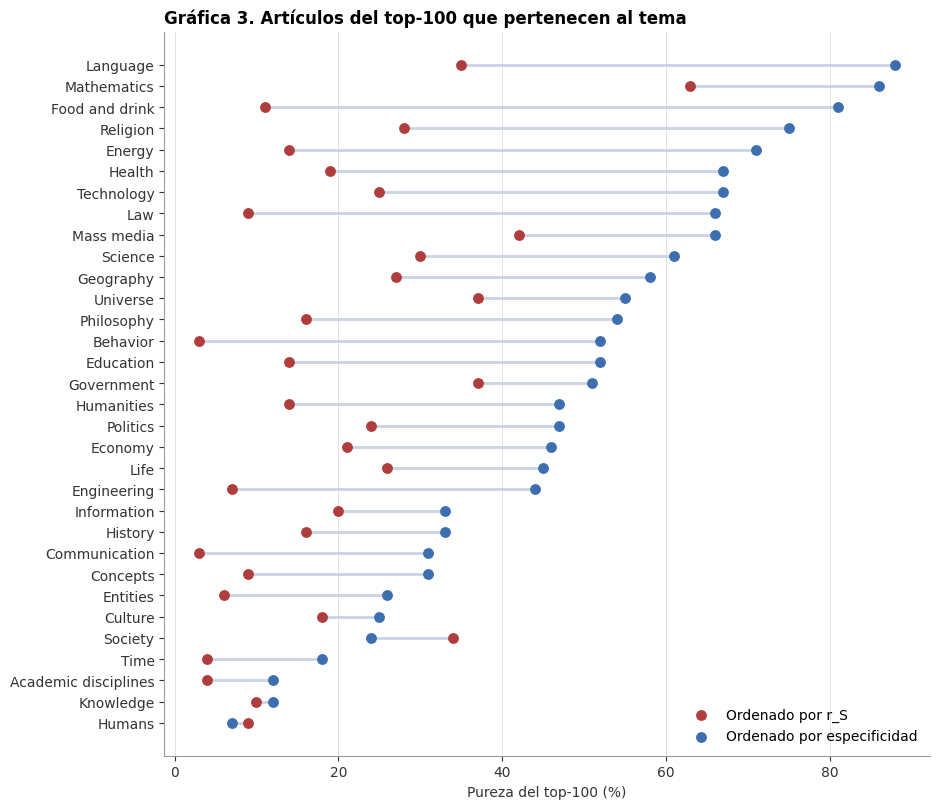

Pureza mediana: 17% con r_S y 49% con especificidad
Temas que mejoran: 30 de 32
Jaccard del top-100 con el PageRank general: mediana 0.481, de 0.099 (Mathematics) a 0.626 (Culture)


In [8]:
# Gráfica 3. Pureza del top-100 con cada orden
inicio = time.time()
por_pureza = masa.sort_values("pureza top-100 con especificidad")
fig, ax = plt.subplots(figsize=(9.5, 8.2))
filas_g = np.arange(K)
ax.hlines(filas_g, 100 * por_pureza["pureza top-100 con r_S"], 100 * por_pureza["pureza top-100 con especificidad"], color="#C9D3E3", linewidth=2)
ax.scatter(100 * por_pureza["pureza top-100 con r_S"], filas_g, s=46, color=ROJO, label="Ordenado por r_S", zorder=3)
ax.scatter(100 * por_pureza["pureza top-100 con especificidad"], filas_g, s=46, color=AZUL, label="Ordenado por especificidad", zorder=3)
ax.set_yticks(filas_g, labels=por_pureza.index)
estilo_ejes(ax, "Gráfica 3. Artículos del top-100 que pertenecen al tema", "Pureza del top-100 (%)", rejilla="x")
ax.legend(loc="lower right")
plt.tight_layout()
archivo_g3 = reg.guardar_figura(fig, "grafica_03_pureza_por_orden", NB)
plt.show()
jac_general = pd.Series({t: jaccard_top(TSPR[:, indice_topico[t]], pr_general, 100) for t in orden})
print(f"Pureza mediana: {masa['pureza top-100 con r_S'].median():.0%} con r_S y {masa['pureza top-100 con especificidad'].median():.0%} con especificidad")
print(f"Temas que mejoran: {(masa['pureza top-100 con especificidad'] > masa['pureza top-100 con r_S']).sum()} de {K}")
print(f"Jaccard del top-100 con el PageRank general: mediana {jac_general.median():.3f}, de {jac_general.min():.3f} ({jac_general.idxmin()}) a {jac_general.max():.3f} ({jac_general.idxmax()})")
reg.registrar_paso("03.3.1", inicio, [archivo_g3], f"pureza mediana {masa['pureza top-100 con especificidad'].median():.0%}")

**Observaciones.** La especificidad mejora 30 de 32 temas, y la pureza mediana pasa de 17 % a 49 %. Los cambios más grandes son *Food and drink* (11 → 81), *Law* (9 → 66) y *Behavior* (3 → 52).

No funciona en todos. *Society* empeora (34 → 24) y *Humans* también (9 → 7), y *Knowledge* y *Academic disciplines* se quedan en 12 %. Son temas muy amplios que no tienen un conjunto de artículos propio y claro.

La tabla de la sección 3 también muestra que el salto sí concentra la probabilidad, sobre todo en temas pequeños: *Philosophy* tiene 79 veces más masa de la que le tocaría por tamaño, y *Humans* apenas 1.07 veces.

La pureza es una medida imperfecta, porque depende de las categorías. Más abajo se ve que *Immanuel Kant* no cuenta como artículo de *Philosophy*.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · TSPR</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3.2 Cuatro temas de ejemplo</span></div>

Los elegimos con un criterio fijo, para no quedarnos solo con los que salen bien: el más grande, el más pequeño, el más cohesivo y el más distinto del PageRank general.

In [9]:
# Selección de los temas de ejemplo y sus 10 primeros con cada orden
inicio = time.time()
lugar_general = pd.Series(pr_general).rank(ascending=False, method="min").astype(int).to_numpy()
candidatos = [("el más grande", list(descripcion.index)),
              ("el más pequeño", list(descripcion.index[::-1])),
              ("el más cohesivo", list(descripcion["cohesión"].sort_values(ascending=False).index)),
              ("el más distinto del general", list(jac_general.sort_values().index))]
representativos = {}
for criterio, lista in candidatos:
    representativos[next(t for t in lista if t not in representativos)] = criterio

archivos_rep = []
for t, criterio in representativos.items():
    col = indice_topico[t]
    crudo, propio = primeros(TSPR[:, col], 10), primeros(especificidad(TSPR[:, col]), 10)
    print(f"{t} ({criterio}): {tam_topico[col]:,} artículos, {tam_semilla[col]:,} semillas")
    tabla = pd.DataFrame({"por r_S": nodos_an.loc[crudo, "title"].to_numpy(), "¿del tema?": np.where(pertenencia[crudo, col], "sí", "no"),
                          "por especificidad": nodos_an.loc[propio, "title"].to_numpy(), "¿del tema? ": np.where(pertenencia[propio, col], "sí", "no"),
                          "lugar general": lugar_general[propio]}, index=pd.RangeIndex(1, 11, name="lugar"))
    display(tabla.style.format({"lugar general": "{:,}"}))
    archivos_rep.append(reg.guardar_tabla(tabla, f"03_2_top10_{t.lower().replace(' ', '_')}", NB))

Humans (el más grande): 1,942,164 artículos, 1,425,388 semillas


,por r_S,¿del tema?,por especificidad,¿del tema?,lugar general
lugar,,,,,
1,Association football,no,Association football,no,4
2,The New York Times,no,Midfielder,no,103
3,United States,no,Defender (association football),no,160
4,World War II,no,Forward (association football),no,192
5,New York City,no,Cricket,no,120
6,The Guardian,no,1988 Summer Olympics,no,979
7,Midfielder,no,Goalkeeper (association football),no,845
8,United Kingdom,no,1992 Summer Olympics,no,964
9,London,no,First-class cricket,no,269


Philosophy (el más pequeño): 17,763 artículos, 15,196 semillas


,por r_S,¿del tema?,por especificidad,¿del tema?,lugar general
lugar,,,,,
1,Philosophy,sí,Philosophy,sí,259
2,The New York Times,no,Contemporary philosophy,sí,"7,007"
3,Western philosophy,sí,Western philosophy,sí,"3,032"
4,United States,no,Ethics,sí,"1,415"
5,Contemporary philosophy,sí,Metaphysics,sí,"2,627"
6,World War II,no,Analytic philosophy,sí,"8,545"
7,Oxford University Press,no,Epistemology,no,"2,524"
8,Academic journal,no,Immanuel Kant,no,"2,214"
9,Latin,no,Aristotle,sí,479


Mathematics (el más cohesivo): 48,835 artículos, 42,014 semillas


,por r_S,¿del tema?,por especificidad,¿del tema?,lugar general
lugar,,,,,
1,Mathematics,sí,Mathematics,sí,154
2,Springer Science+Business Media,no,Real number,sí,"1,368"
3,Real number,sí,American Mathematical Society,sí,"3,977"
4,Cambridge University Press,no,Springer Science+Business Media,no,257
5,American Mathematical Society,sí,Mathematician,sí,"2,092"
6,Mathematician,sí,Integer,sí,"2,002"
7,Integer,sí,Complex number,sí,"2,268"
8,Academic journal,no,Natural number,sí,"3,636"
9,United States,no,Function (mathematics),sí,"1,829"


Universe (el más distinto del general): 39,497 artículos, 13,187 semillas


,por r_S,¿del tema?,por especificidad,¿del tema?,lugar general
lugar,,,,,
1,Chemical formula,no,Chemical formula,no,"1,751"
2,Protein,sí,Ion,sí,945
3,United States,no,Protein,sí,151
4,Ion,sí,Electron,sí,"1,386"
5,The New York Times,no,Oxygen,sí,538
6,Gene,no,Hydrogen,sí,899
7,World War II,no,Atom,sí,"1,835"
8,Oxygen,sí,Gene,no,182
9,Electron,sí,Chemistry,no,395


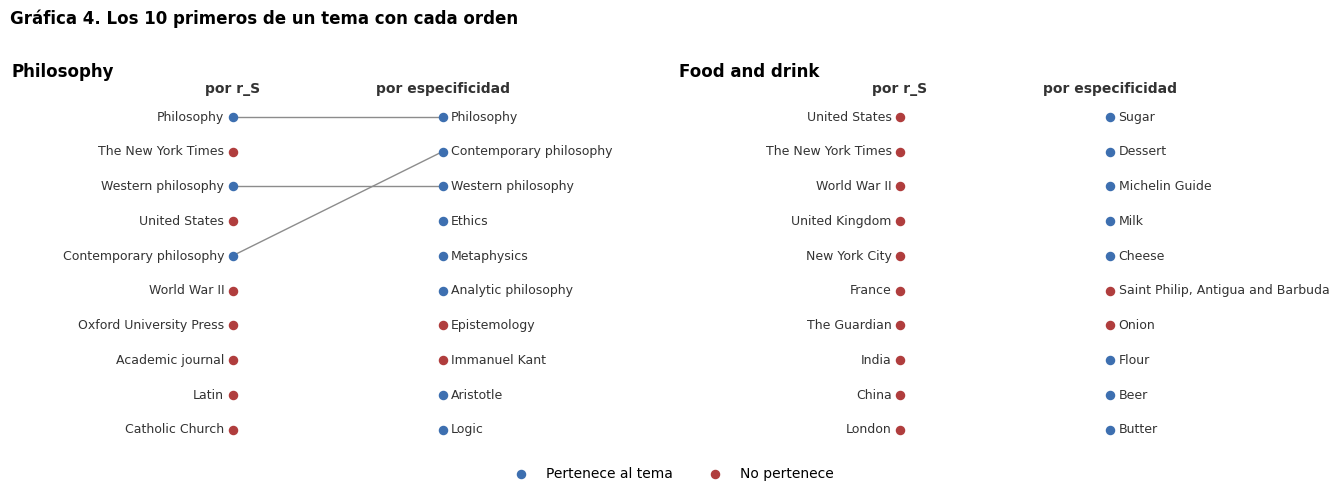

,artículo,enlaces recibidos,lugar en el tema,lugar general
tema,,,,
Humans,Italian name,"1,710.0",86,"11,775"
Philosophy,Nikoli (publisher),43.0,86,"480,915"
Mathematics,Functor,524.0,89,"25,338"
Universe,Mixed-anion compounds,77.0,20,"381,178"


In [10]:
# Gráfica 4. Antes y después: los 10 primeros de un tema con cada orden
def comparar_ordenes(ax, tema):
    col = indice_topico[tema]
    crudo, propio = list(primeros(TSPR[:, col], 10)), list(primeros(especificidad(TSPR[:, col]), 10))
    for lado, lista in ((0, crudo), (1, propio)):
        for pos, i in enumerate(lista):
            color = AZUL if pertenencia[i, col] else ROJO
            ax.scatter(lado, pos, s=34, color=color, zorder=3)
            ax.text(lado - 0.04 if lado == 0 else lado + 0.04, pos, nodos_an.loc[i, "title"][:38], ha="right" if lado == 0 else "left",
                    va="center", fontsize=9, color=TINTA)
    for i in set(crudo) & set(propio):
        ax.plot([0, 1], [crudo.index(i), propio.index(i)], color=GRIS, linewidth=1, zorder=1)
    ax.set_xlim(-1.05, 2.05)
    ax.set_ylim(9.6, -0.9)
    ax.axis("off")
    ax.set_title(tema)
    ax.text(0, -0.7, "por r_S", ha="center", fontweight="bold", color=TINTA)
    ax.text(1, -0.7, "por especificidad", ha="center", fontweight="bold", color=TINTA)

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.9))
for ax, tema in zip(ejes, ["Philosophy", "Food and drink"]):
    comparar_ordenes(ax, tema)
ejes[0].scatter([], [], s=34, color=AZUL, label="Pertenece al tema")
ejes[0].scatter([], [], s=34, color=ROJO, label="No pertenece")
fig.legend(loc="lower center", ncol=2, frameon=False)
fig.suptitle("Gráfica 4. Los 10 primeros de un tema con cada orden", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(rect=(0, 0.05, 1, 0.97))
reg.guardar_figura(fig, "grafica_04_antes_y_despues", NB)
plt.show()

# Artículos propios del tema que más suben respecto al PageRank general
filas_suben = []
for t in representativos:
    col = indice_topico[t]
    lugar_t = pd.Series(especificidad(TSPR[:, col])).rank(ascending=False, method="min").astype(int).to_numpy()
    propios = [i for i in primeros(especificidad(TSPR[:, col]), 100) if pertenencia[i, col]]
    mejor = max(propios, key=lambda i: lugar_general[i] - lugar_t[i])
    filas_suben.append({"tema": t, "artículo": nodos_an.loc[mejor, "title"], "enlaces recibidos": k_in[mejor],
                        "lugar en el tema": lugar_t[mejor], "lugar general": lugar_general[mejor]})
tabla_suben = pd.DataFrame(filas_suben).set_index("tema")
display(tabla_suben.style.format({"enlaces recibidos": "{:,}", "lugar general": "{:,}"}))
reg.registrar_paso("03.3.2", inicio, archivos_rep + [reg.guardar_tabla(tabla_suben, "03_2_los_que_mas_suben", NB)],
                   "; ".join(f"{t} ({x})" for t, x in representativos.items()))

**Observaciones.** En *Food and drink* ninguno de los 10 primeros pertenece al tema si ordenamos por $r_S$, y 8 de ellos también están en el top-10 del PageRank general. Con especificidad son 8 de 10: *Sugar*, *Dessert*, *Milk*, *Cheese*. En *Philosophy* pasan de 3 a 8, y solo *Philosophy* y *Western philosophy* conservan su lugar.

Los puntos rojos de la derecha no siempre son errores. *Epistemology* e *Immanuel Kant* sí son filosofía y *Onion* sí es comida, pero las categorías los asignaron a otro tema más cercano. *Saint Philip, Antigua and Barbuda* sí es un error, y no lo corregimos a mano.

En los otros temas de ejemplo:

- *Mathematics* es el caso que mejor funciona (9 de 10), aunque *Springer Science+Business Media* sigue arriba.
- *Universe* resulta ser sobre todo química y materia: *Ion*, *Electron*, *Hydrogen*, *Atom*. Refleja cómo se organizan las categorías, y no lo que uno imaginaría por el nombre.
- *Humans* falla: su lista es de deportes (*Midfielder*, *Cricket*, *1988 Summer Olympics*), porque muchas biografías son de deportistas y enlazan a estos artículos.

En la tabla de los que más suben también hay aciertos y ruido: *Functor* pasa del lugar 25,338 al 89 dentro de *Mathematics*, mientras que *Nikoli (publisher)*, una editorial de acertijos, llega al 86 de *Philosophy*.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · HITS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4. HITS dentro de cada tema</span></div>

En el notebook 2, HITS sobre toda Wikipedia se queda en el núcleo general. Para ver cómo funciona dentro de un tema, lo corremos solo con los enlaces entre las semillas de ese tema. Las fórmulas son las mismas, con $A_S$, la parte de la matriz que conecta artículos de $S$:

$$a \leftarrow A_S^\top h \qquad\qquad h \leftarrow A_S\,a$$

Como no salimos del tema, el núcleo general no puede entrar, aunque también dejamos fuera a los artículos del tema que están a más de 5 niveles.

In [11]:
# HITS dentro de las semillas de cada tema
inicio = time.time()
A_an = sp.vstack(A_bloques, format="csr")
def hits_tema(tema, tol=1e-8, max_iter=500):
    """HITS sobre el subgrafo de las semillas de un tema. Devuelve índices, hubs, autoridades, iteraciones y la submatriz."""
    indices = np.where(semilla[:, indice_topico[tema]])[0]
    G = A_an[indices][:, indices].tocsr()
    h = np.full(len(indices), 1 / len(indices))
    for iteracion in range(1, max_iter + 1):
        a = G.T @ h
        a /= a.sum()
        nuevo = G @ a
        nuevo /= nuevo.sum()
        error = np.abs(nuevo - h).sum()
        h = nuevo
        if error < tol:
            break
    a = G.T @ h
    return indices, h, a / a.sum(), iteracion, G


filas_hits, resultados_hits = [], {}
for tema in orden:
    t0 = time.perf_counter()
    resultados_hits[tema] = hits_tema(tema)
    indices, h, a, iteraciones, G = resultados_hits[tema]
    top_h, top_a = np.argsort(-h)[:10], np.argsort(-a)[:10]
    filas_hits.append({"tema": tema, "semillas": len(indices), "enlaces": G.nnz, "iteraciones": iteraciones, "segundos": round(time.perf_counter() - t0, 1),
                       "autoridades": ", ".join(nodos_an.loc[indices[top_a[:6]], "title"]), "hubs": ", ".join(nodos_an.loc[indices[top_h[:6]], "title"]),
                       "en ambos top-10": len(np.intersect1d(top_h, top_a))})
tabla_hits_tema = pd.DataFrame(filas_hits).set_index("tema")
pd.set_option("display.max_colwidth", 110)
display(tabla_hits_tema.loc[["Mathematics", "Philosophy", "Food and drink", "Universe", "Science", "History"]])
reg.guardar_tabla(tabla_hits_tema, "04_hits_por_tema", NB)

,semillas,enlaces,iteraciones,segundos,autoridades,hubs,en ambos top-10
tema,,,,,,,
Mathematics,42014,708690,18,0.1,"Mathematics, Real number, Complex number, American Mathematical Society, Integer, Vector space","Glossary of areas of mathematics, Mathematics, Vector space, History of mathematics, List of theorems, Lis...",3
Philosophy,15196,105344,19,0.1,"Philosophy, Western philosophy, Contemporary philosophy, Ethics, Metaphysics, Aristotle","Western philosophy, Timeline of Western philosophers, History of philosophy, Glossary of philosophy, Germa...",2
Food and drink,67281,637994,17,0.1,"Potato, Sugar, Rice, Garlic, Pork, Eggs as food","American cuisine, List of snack foods, Canadian cuisine, List of Good Eats episodes, List of Christmas dis...",0
Universe,13187,102708,25,0.0,"Hydrogen, Oxygen, Electron, Ion, Iron, Carbon","Chemical element, Heavy metals, Atomic radius, Electron shell, Atom, Neptunium",1
Science,89870,693455,17,0.2,"Constellation, Apparent magnitude, Light-year, Stellar classification, Epoch (astronomy), Effective temper...","Glossary of astronomy, Betelgeuse, Epsilon Eridani, Aldebaran, List of astronomy acronyms, Rigel",1
History,196932,1884306,54,0.7,"Russian Empire, Catholic Church, United Kingdom of Great Britain and Ireland, North Sea, Brig, Qing dynasty","Timeline of the 20th century, 1944, Timeline of geopolitical changes (1500–1899), 1920, 1916, 1940",0


WindowsPath('C:/Users/PC/Documents/IIMAS/Datos Masivos II/Práctica 3/T3_DMII/Wikipedia/data/resultados/03_topic_sensitive/04_hits_por_tema.csv')

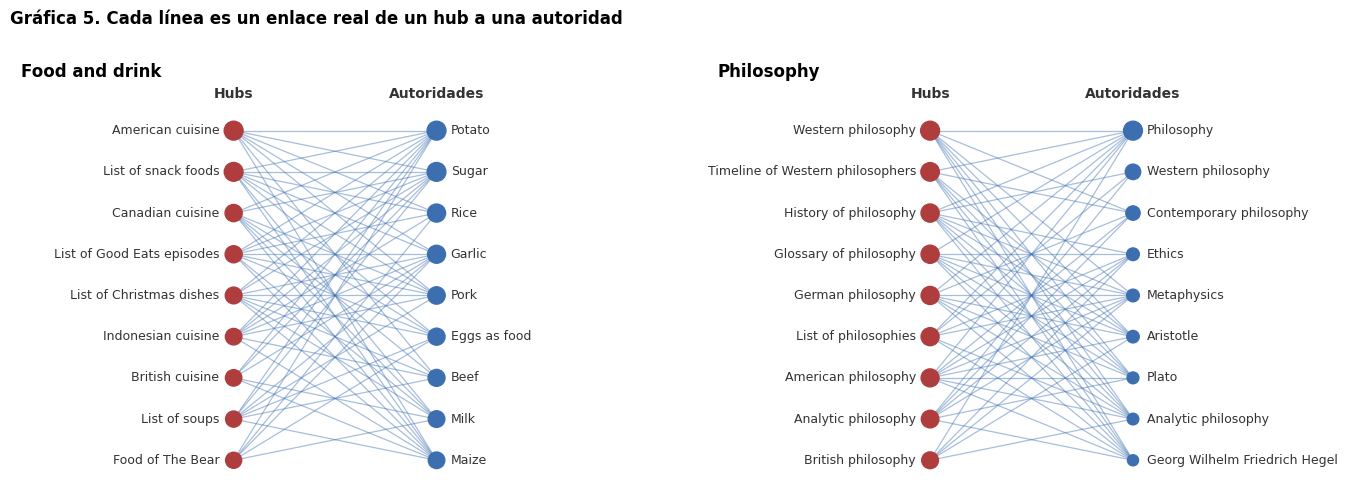

{'Food and drink': '77% de los enlaces posibles', 'Philosophy': '74% de los enlaces posibles'}


In [12]:
# Gráfica 5. Hubs y autoridades de un tema, con sus enlaces reales
def dibujar_hits(ax, tema, k=9):
    indices, h, a, _, G = resultados_hits[tema]
    top_h, top_a = np.argsort(-h)[:k], np.argsort(-a)[:k]
    sub = G[top_h][:, top_a].toarray()
    y = np.arange(k)
    for f, col in zip(*np.nonzero(sub)):
        ax.plot([0, 1], [f, col], color=AZUL, linewidth=0.9, alpha=0.45, zorder=1)
    ax.scatter(np.zeros(k), y, s=4000 * h[top_h] / h[top_h].max() * 0.04 + 25, color=ROJO, zorder=3)
    ax.scatter(np.ones(k), y, s=4000 * a[top_a] / a[top_a].max() * 0.04 + 25, color=AZUL, zorder=3)
    for pos, i in enumerate(top_h):
        ax.text(-0.07, pos, nodos_an.loc[indices[i], "title"][:32], ha="right", va="center", fontsize=9, color=TINTA)
    for pos, i in enumerate(top_a):
        ax.text(1.07, pos, nodos_an.loc[indices[i], "title"][:32], ha="left", va="center", fontsize=9, color=TINTA)
    ax.set_xlim(-1.05, 2.05)
    ax.set_ylim(k - 0.4, -1.1)
    ax.axis("off")
    ax.set_title(tema)
    ax.text(0, -0.8, "Hubs", ha="center", fontweight="bold", color=TINTA)
    ax.text(1, -0.8, "Autoridades", ha="center", fontweight="bold", color=TINTA)
    return sub

fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
densidades = {}
for ax, tema in zip(ejes, ["Food and drink", "Philosophy"]):
    sub = dibujar_hits(ax, tema)
    densidades[tema] = sub.mean()
fig.suptitle("Gráfica 5. Cada línea es un enlace real de un hub a una autoridad", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.97))
reg.guardar_figura(fig, "grafica_05_hits_por_tema", NB)
plt.show()
print({t: f"{d:.0%} de los enlaces posibles" for t, d in densidades.items()})
reg.registrar_paso("03.HITS", inicio, [reg.carpeta(NB) / "04_hits_por_tema.csv"], f"{K} temas")
del A_an, resultados_hits

**Observaciones.** Ahora los dos papeles de HITS se entienden a simple vista. En *Food and drink*, los hubs son páginas de cocina y listas (*American cuisine*, *List of snack foods*), y las autoridades son ingredientes (*Potato*, *Sugar*, *Rice*). Ninguno de sus 10 primeros tiene los dos papeles. En *Philosophy* sí hay cruce: *Western philosophy* y *Analytic philosophy* aparecen en ambos lados.

El bloque es denso: entre estos 9 × 9 existe el 77 % de los enlaces posibles en *Food and drink* y el 74 % en *Philosophy*. Ya no aparecen *United States* ni *The New York Times* en estos dos temas.

La tabla de los 32 temas muestra el límite: HITS encuentra el bloque más denso, que no siempre representa a todo el tema. En *Science* se queda con astronomía (*Constellation*, *Betelgeuse*), en *Life* con botánica (*Sepal*, *Bract*) y en *Communication* con dominios de internet (*.uk*, *.eu*). En temas amplios como *Society* o *Government*, *United States* y otros países siguen siendo las principales autoridades. Es muy barato: los 32 temas tardan 17 segundos en total.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · TSPR</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">5. Un lector con varios intereses</span></div>

Si un lector se interesa 70 % por un tema y 30 % por otro, no hace falta calcular otro PageRank. Basta con combinar los vectores que ya tenemos:

$$r_{\text{lector}} \approx \sum_T w_T \, r_{S_T}, \qquad \sum_T w_T = 1, \quad w_T \ge 0$$

Esto funciona porque en la fórmula de PageRank el salto entra de forma lineal. Si el salto del lector es una mezcla de saltos, su resultado es la misma mezcla de resultados.

No es una igualdad exacta porque la probabilidad de los colgantes regresa al tema de cada vector. Medimos el error comparando contra el cálculo directo. Después ordenamos el resultado con la especificidad, calculada sobre los 6.88 millones de artículos.

,70 % Science + 30 % History
‖mezcla − directo‖₁,1.29e-04
Error relativo máximo en el top-100,0.02 %
Jaccard top-100,1.000
Spearman ρ (todos),1.0000


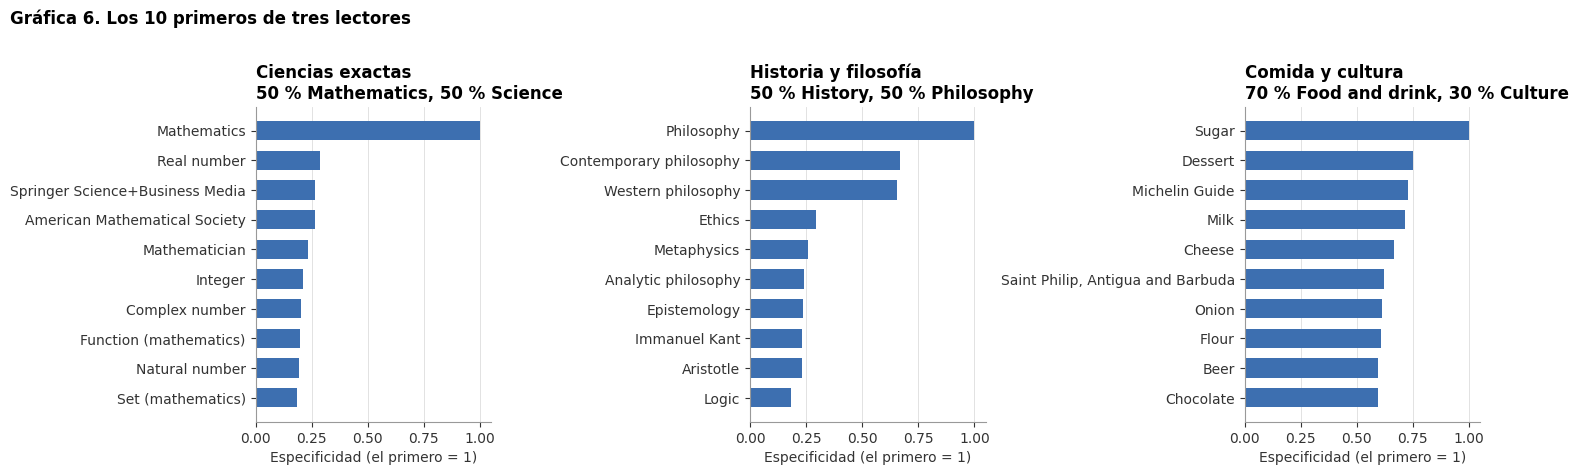

,Ciencias exactas,Historia y filosofía,Comida y cultura
lugar,,,
1,Mathematics,Philosophy,Sugar
2,Real number,Contemporary philosophy,Dessert
3,Springer Science+Business Media,Western philosophy,Michelin Guide
4,American Mathematical Society,Ethics,Milk
5,Mathematician,Metaphysics,Cheese
6,Integer,Analytic philosophy,"Saint Philip, Antigua and Barbuda"
7,Complex number,Epistemology,Onion
8,Function (mathematics),Immanuel Kant,Flour
9,Natural number,Aristotle,Beer


In [13]:
# Mezcla de temas contra el cálculo directo, y tres perfiles de lector
inicio = time.time()
pesos = {"Science": 0.7, "History": 0.3}
r_mezcla = sum(w * TSPR[:, indice_topico[t]] for t, w in pesos.items())
v_usuario = sum(w * S[:, indice_topico[t]] / tam_semilla[indice_topico[t]] for t, w in pesos.items())
r_directo, _ = pagerank_topicos(v_usuario[:, None], tol=1e-10)
r_directo = r_directo[:, 0]
top_directo = primeros(r_directo, 100)
mezcla = pd.Series({
    "‖mezcla − directo‖₁": f"{np.abs(r_mezcla - r_directo).sum():.2e}",
    "Error relativo máximo en el top-100": pct((np.abs(r_mezcla - r_directo)[top_directo] / r_directo[top_directo]).max(), 2),
    "Jaccard top-100": f"{jaccard_top(r_mezcla, r_directo, 100):.3f}",
    "Spearman ρ (todos)": f"{spearmanr(r_mezcla, r_directo).statistic:.4f}",
}, name="70 % Science + 30 % History").to_frame()
display(mezcla)
del r_directo, v_usuario, r_mezcla

perfiles = {"Ciencias exactas": {"Mathematics": 0.5, "Science": 0.5},
            "Historia y filosofía": {"History": 0.5, "Philosophy": 0.5},
            "Comida y cultura": {"Food and drink": 0.7, "Culture": 0.3}}
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.8))
tablas_perfil = {}
for ax, (nombre, w) in zip(ejes, perfiles.items()):
    r_p = sum(p * TSPR[:, indice_topico[t]] for t, p in w.items())
    puntaje = especificidad(r_p)
    top = primeros(puntaje, 10)
    tablas_perfil[nombre] = nodos_an.loc[top, "title"].to_numpy()
    ax.barh([t[:36] for t in tablas_perfil[nombre][::-1]], puntaje[top][::-1] / puntaje[top][0], color=AZUL, height=0.65)
    estilo_ejes(ax, nombre + "\n" + ", ".join(f"{int(100 * p)} % {t}" for t, p in w.items()), "Especificidad (el primero = 1)", rejilla="x")
    ax.title.set_fontsize(10)
fig.suptitle("Gráfica 6. Los 10 primeros de tres lectores", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.97))
archivo_g6 = reg.guardar_figura(fig, "grafica_06_lectores", NB)
plt.show()
tabla_perfiles = pd.DataFrame(tablas_perfil, index=pd.RangeIndex(1, 11, name="lugar"))
display(tabla_perfiles)
reg.registrar_paso("03.5", inicio, [reg.guardar_tabla(mezcla, "05_mezcla", NB), reg.guardar_tabla(tabla_perfiles, "05_perfiles", NB), archivo_g6],
                   f"‖mezcla − directo‖₁ = {mezcla.iloc[0, 0]}")
del TSPR

**Observaciones.** La mezcla reproduce el cálculo directo: la diferencia total es de 1.29e-04, el error máximo en el top-100 es de 0.02 % y los dos top-100 son idénticos. Así se puede responder a cualquier combinación de temas sin volver a correr PageRank.

Los perfiles muestran un problema: los pesos no se traducen en una lista repartida. El lector de "Historia y filosofía" pide 50 % de cada uno y recibe solo filosofía. Con 15,196 semillas contra 196,932, cada semilla de *Philosophy* recibe 13 veces más probabilidad que una de *History*. Lo mismo pasa con *Mathematics* frente a *Science*, y *Food and drink* frente a *Culture*.

Si se quisiera una lista balanceada, habría que tomar lugares de cada tema por separado, en vez de mezclar los puntajes. *Saint Philip, Antigua and Barbuda* vuelve a aparecer en el tercer perfil, porque la mezcla hereda los errores de cada tema.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · VALIDACIÓN</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">6. ¿Los puntajes permiten adivinar el tema?</span></div>

Si el PageRank de un tema mide la cercanía con ese tema, el tema con mayor puntaje debería ser el real. Lo probamos así:

1. Ocultamos el 20 % de los artículos con tema (semilla aleatoria 42) y los quitamos de las semillas y de las etiquetas.
2. Recalculamos los 32 vectores.
3. Para cada artículo oculto elegimos un tema. Acierta si es uno de sus temas reales.

Comparamos cinco formas de elegir:

- **Tema más grande:** siempre el mismo. Es la línea base.
- **Voto de vecinos:** el tema más frecuente entre los artículos etiquetados que lo enlazan o a los que enlaza.
- **Mayor $r_T(i)$:** el tema con más puntaje en ese artículo.
- **Corregido por tamaño:** un tema pequeño concentra su puntaje en pocas semillas y sale favorecido. Con la regla de Bayes, la probabilidad del tema dado el artículo es proporcional a $r_T(i)$ por el tamaño del tema:

$$\hat{T}(i) = \arg\max_T \; r_T(i)\,|S_T|$$

- **Percentil dentro del tema:** el tema donde el artículo está más arriba en la lista completa de ese tema.

Vectores con 1,310,735 artículos ocultos: 61 iteraciones en 12.3 min


,Tema más grande (Humans),Mayor r_T,Corregido por tamaño,Percentil dentro del tema,Voto de vecinos
"todos los ocultos (1,310,735)",29.6%,39.2%,37.5%,31.8%,48.3%
"con algún vecino etiquetado (1,309,811)",29.6%,39.3%,37.5%,31.8%,48.3%
sin vecinos etiquetados (924),21.8%,18.0%,17.4%,17.2%,—


,artículos ocultos del tema,predichos con mayor r_T,predichos corregido,precisión con mayor r_T,precisión corregido
tema,,,,,
Humans,"387,346","186,700","933,693",53.8%,32.3%
Culture,"265,866","37,292","23,277",33.2%,45.8%
Geography,"206,837","103,926","40,130",69.5%,65.1%
Society,"187,380","12,736","9,287",38.1%,38.7%
Mass media,"170,088","133,265","78,149",63.9%,67.5%
Government,"163,555","57,875","29,799",54.2%,59.4%
History,"140,475","36,496","11,281",38.1%,45.4%
Humanities,"89,849","35,454","11,274",43.3%,57.0%
Technology,"74,791","22,791","15,933",51.6%,64.5%


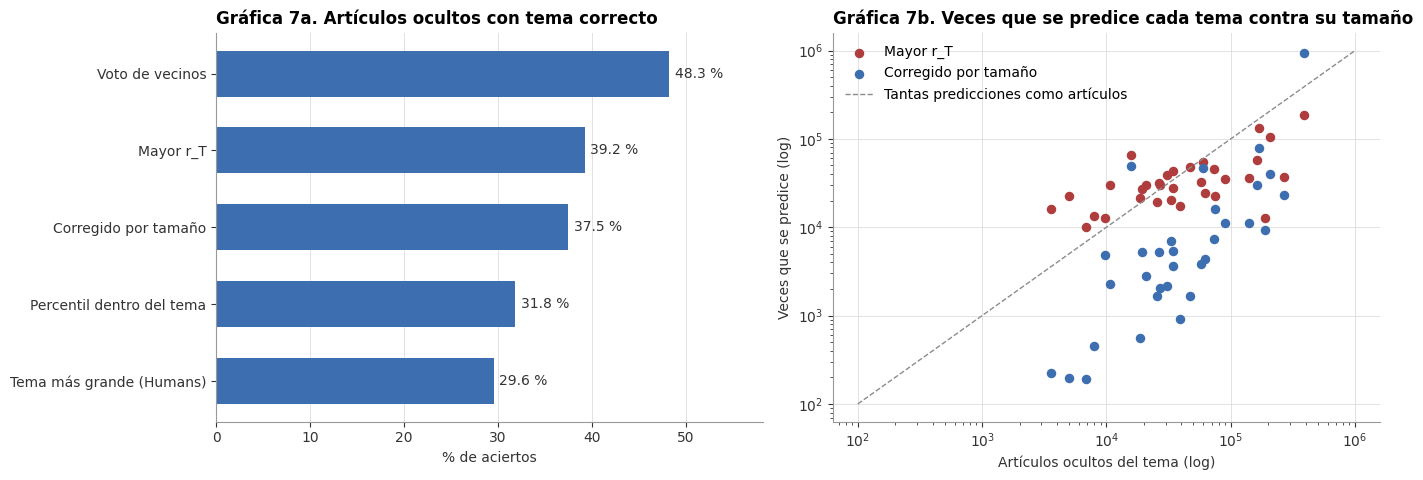

In [14]:
# Ocultar el 20 % de los artículos con tema, recalcular los vectores y predecir
inicio = time.time()
rng = np.random.default_rng(SEMILLA)
etiquetados = np.where(con_topico)[0]
ocultos = rng.choice(etiquetados, size=int(0.2 * len(etiquetados)), replace=False)
S_entreno = S.copy()
S_entreno[ocultos] = 0
P_entreno = P.copy()
P_entreno[ocultos] = 0
del S
t0 = time.perf_counter()
TSPR_entreno, it_entreno = pagerank_topicos(S_entreno)
print(f"Vectores con {len(ocultos):,} artículos ocultos: {it_entreno} iteraciones en {(time.perf_counter() - t0) / 60:.1f} min")

en_ocultos = TSPR_entreno[ocultos]
pred_crudo = en_ocultos.argmax(axis=1)
tam_entreno = S_entreno.sum(axis=0, dtype=np.float64)
pred_bayes = (en_ocultos * tam_entreno).argmax(axis=1)
percentil = np.stack([np.searchsorted(np.sort(TSPR_entreno[:, t]), en_ocultos[:, t]) / n for t in range(K)], axis=1)
pred_percentil = percentil.argmax(axis=1)
del TSPR_entreno, percentil

mayor = P_entreno.sum(axis=0).argmax()
votos = (producto(A_bloques, P_entreno) + producto(AT_bloques, P_entreno))[ocultos]
con_vecinos = votos.sum(axis=1) > 0
pred_vecinos = votos.argmax(axis=1)
del votos, P_entreno, S_entreno, en_ocultos

acierta = lambda pred: pertenencia[ocultos, pred]
aciertos = {f"Tema más grande ({TOPICOS[mayor]})": acierta(np.full(len(ocultos), mayor)),
            "Mayor r_T": acierta(pred_crudo), "Corregido por tamaño": acierta(pred_bayes),
            "Percentil dentro del tema": acierta(pred_percentil), "Voto de vecinos": con_vecinos & acierta(pred_vecinos)}
validacion = pd.DataFrame({nombre: {f"todos los ocultos ({len(ocultos):,})": x.mean(), f"con algún vecino etiquetado ({con_vecinos.sum():,})": x[con_vecinos].mean(),
                                    f"sin vecinos etiquetados ({(~con_vecinos).sum():,})": x[~con_vecinos].mean()} for nombre, x in aciertos.items()})
validacion.loc[validacion.index[2], "Voto de vecinos"] = np.nan
display(validacion.style.format("{:.1%}", na_rep="—"))

por_topico = pd.DataFrame({
    "artículos ocultos del tema": pertenencia[ocultos].sum(axis=0),
    "predichos con mayor r_T": np.bincount(pred_crudo, minlength=K),
    "predichos corregido": np.bincount(pred_bayes, minlength=K),
    "precisión con mayor r_T": [acierta(pred_crudo)[pred_crudo == t].mean() if (pred_crudo == t).any() else np.nan for t in range(K)],
    "precisión corregido": [acierta(pred_bayes)[pred_bayes == t].mean() if (pred_bayes == t).any() else np.nan for t in range(K)],
}, index=pd.Index(TOPICOS, name="tema")).loc[orden]
display(por_topico.style.format({"artículos ocultos del tema": "{:,}", "predichos con mayor r_T": "{:,}", "predichos corregido": "{:,}",
                                 "precisión con mayor r_T": "{:.1%}", "precisión corregido": "{:.1%}"}, na_rep="—"))

# Gráfica 7. Aciertos por método y sesgo hacia los temas pequeños
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.9))
primera = validacion.iloc[0].sort_values()
ax1.barh(primera.index, 100 * primera.to_numpy(), color=AZUL, height=0.6)
for y, valor in enumerate(100 * primera.to_numpy()):
    ax1.text(valor + 0.6, y, f"{valor:.1f} %", va="center", color=TINTA)
ax1.set_xlim(0, 100 * primera.max() + 10)
estilo_ejes(ax1, "Gráfica 7a. Artículos ocultos con tema correcto", "% de aciertos", rejilla="x")
reales = por_topico["artículos ocultos del tema"].to_numpy()
ax2.scatter(reales, por_topico["predichos con mayor r_T"].clip(lower=1), s=34, color=ROJO, label="Mayor r_T")
ax2.scatter(reales, por_topico["predichos corregido"].clip(lower=1), s=34, color=AZUL, label="Corregido por tamaño")
limites = [1e2, 1e6]
ax2.plot(limites, limites, color=GRIS, linestyle="--", linewidth=1, label="Tantas predicciones como artículos")
ax2.set_xscale("log")
ax2.set_yscale("log")
estilo_ejes(ax2, "Gráfica 7b. Veces que se predice cada tema contra su tamaño", "Artículos ocultos del tema (log)", "Veces que se predice (log)", rejilla="both")
ax2.legend(loc="upper left")
plt.tight_layout()
archivo_g7 = reg.guardar_figura(fig, "grafica_07_validacion", NB)
plt.show()
reg.registrar_paso("03.4", inicio, [reg.guardar_tabla(validacion, "06_validacion", NB), reg.guardar_tabla(por_topico, "06_validacion_por_tema", NB), archivo_g7],
                   ", ".join(f"{k}: {v.mean():.1%}" for k, v in aciertos.items()))
POOL.shutdown()

**Observaciones.** El método más simple es el mejor: el voto de vecinos acierta 48.3 %, contra 39.2 % de $r_T$ y 29.6 % de la línea base. Los puntajes sí contienen información sobre el tema, pero para etiquetar basta con mirar a los vecinos directos.

La corrección por tamaño no mejora el total (37.5 %). En 7b se ve lo que hace: cambia un sesgo por otro. Sin corregir, los temas pequeños se predicen de más: *Philosophy* 16,118 veces, para 3,558 artículos, con precisión de 12.1 %. Corregido, se predice mucho más *Humans*: 933,693 veces, para 387,346 artículos.

Lo que sí mejora es la precisión de varios temas cuando se predicen: *Food and drink* pasa de 35.4 % a 71.3 %, y *Mathematics* de 50.2 % a 82.9 %. Esto tiene un costo: *Philosophy* solo se predice 226 veces, así que deja sin detectar a casi todos sus artículos.

El percentil dentro del tema apenas supera la línea base (31.8 %). En conjunto, estos vectores sirven para ordenar artículos dentro de un tema, más que para decidir de qué tema es un artículo. El 99.9 % de los artículos ocultos tiene algún vecino etiquetado, y por eso el voto de vecinos casi siempre puede responder.

Las conclusiones de toda la práctica están al final de `04_recomendaciones.ipynb`.